# Part D3 — The normalized choropleth (9 marks)

`district_health.csv` + `districts.geojson` — the six-step recipe from slide 50:
**project → join (count failures) → normalize → classify → colour → caption**, then put the *count* back beside the map.

In [1]:
import os, sys, json, itertools
sys.path.insert(0, os.getcwd())          # notebook sits beside vizlib.py / geolib.py
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geolib as g                        # Week 5 toolkit (built on vizlib)
g.style_defaults()                        # Week 3 look, 300 dpi export default
DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
PAL = g.PALETTE

def corr_chain(df, cols):
    """geolib.corr_chain with one line changed: newer pandas hands back a read-only
    array, so np.fill_diagonal on r.values raises. Same greedy rule (slide 24)."""
    cols = list(cols)
    r = df[cols].corr().abs()
    a = r.to_numpy().copy(); np.fill_diagonal(a, 0.0)
    r = pd.DataFrame(a, index=cols, columns=cols)
    i, j = np.unravel_index(np.argmax(a), a.shape)
    order = [cols[i], cols[j]]
    while len(order) < len(cols):
        rest = [c for c in cols if c not in order]
        order.append(max(rest, key=lambda c: r.loc[order[-1], c]))
    return order

NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]

In [2]:
# 1 ── PROJECT. geolib.choropleth() projects with Lambert cylindrical equal-area, one shared standard parallel.
feats = g.read_geojson(DATA + "districts.geojson")
lat_ts = float(np.mean([p[1] for f in feats for p in f["ring"]]))
print(f"projection: Lambert cylindrical equal-area, standard parallel {lat_ts:.2f}°N (mean latitude of all vertices)")

# 2 ── JOIN on code, and COUNT the failures both ways
dh = pd.read_csv(DATA + "district_health.csv")
geo_codes, tab_codes = {f["code"] for f in feats}, set(dh.code)
print("features:", len(geo_codes), "| table rows:", len(tab_codes))
print("geometry with no data row :", sorted(geo_codes - tab_codes))
print("data row with no geometry :", sorted(tab_codes - geo_codes))
fails = len(geo_codes ^ tab_codes)
print("JOIN FAILURES:", fails)
assert fails == 0 and len(dh) == 24

projection: Lambert cylindrical equal-area, standard parallel 30.50°N (mean latitude of all vertices)
features: 24 | table rows: 24
geometry with no data row : []
data row with no geometry : []
JOIN FAILURES: 0


In [3]:
# 3 ── NORMALIZE: cases per 100,000 residents
dh["rate"] = dh.cases / dh.population * 1e5
pooled = dh.cases.sum() / dh.population.sum() * 1e5     # pooled, NOT the mean of 24 rates
print(f"cases {dh.cases.sum():,} | population {dh.population.sum():,} | pooled national rate {pooled:.1f} per 100,000")
print(f"r(cases, population) = {dh.cases.corr(dh.population):+.3f}   r(rate, population) = {dh.rate.corr(dh.population):+.3f}")
print("top 3 by COUNT:", dh.nlargest(3,"cases").code.tolist(), " top 3 by RATE:", dh.nlargest(3,"rate").code.tolist(),
      " overlap =", len(set(dh.nlargest(3,'cases').code) & set(dh.nlargest(3,'rate').code)))

# 4 ── CLASSIFY: score the three schemes, then choose one and name it
for sch in ("equal", "quantile", "natural"):
    e = g.breaks(dh.rate, sch, 5)
    print(f"{sch:9s} GVF = {g.gvf(dh.rate, e):.3f}  breaks = {np.round(e, 1).tolist()}")

cases 30,564 | population 57,857,000 | pooled national rate 52.8 per 100,000
r(cases, population) = +0.986   r(rate, population) = -0.000
top 3 by COUNT: ['D17', 'D13', 'D09']  top 3 by RATE: ['D19', 'D20', 'D21']  overlap = 0
equal     GVF = 0.969  breaks = [30.4, 39.6, 48.9, 58.1, 67.3, 76.5]
quantile  GVF = 0.908  breaks = [30.4, 43.8, 49.8, 54.1, 63.0, 76.5]
natural   GVF = 0.969  breaks = [30.4, 33.8, 47.5, 54.4, 64.8, 76.5]


**Scheme chosen: natural breaks (Jenks), k = 5** — the rates have visible gaps, and Jenks has the highest goodness-of-variance-fit by construction
(printed above: equal-interval ties closely, quantile is lowest). The five break edges are printed in the legend.

printed class breaks: [30.4, 33.8, 47.5, 54.4, 64.8, 76.5]


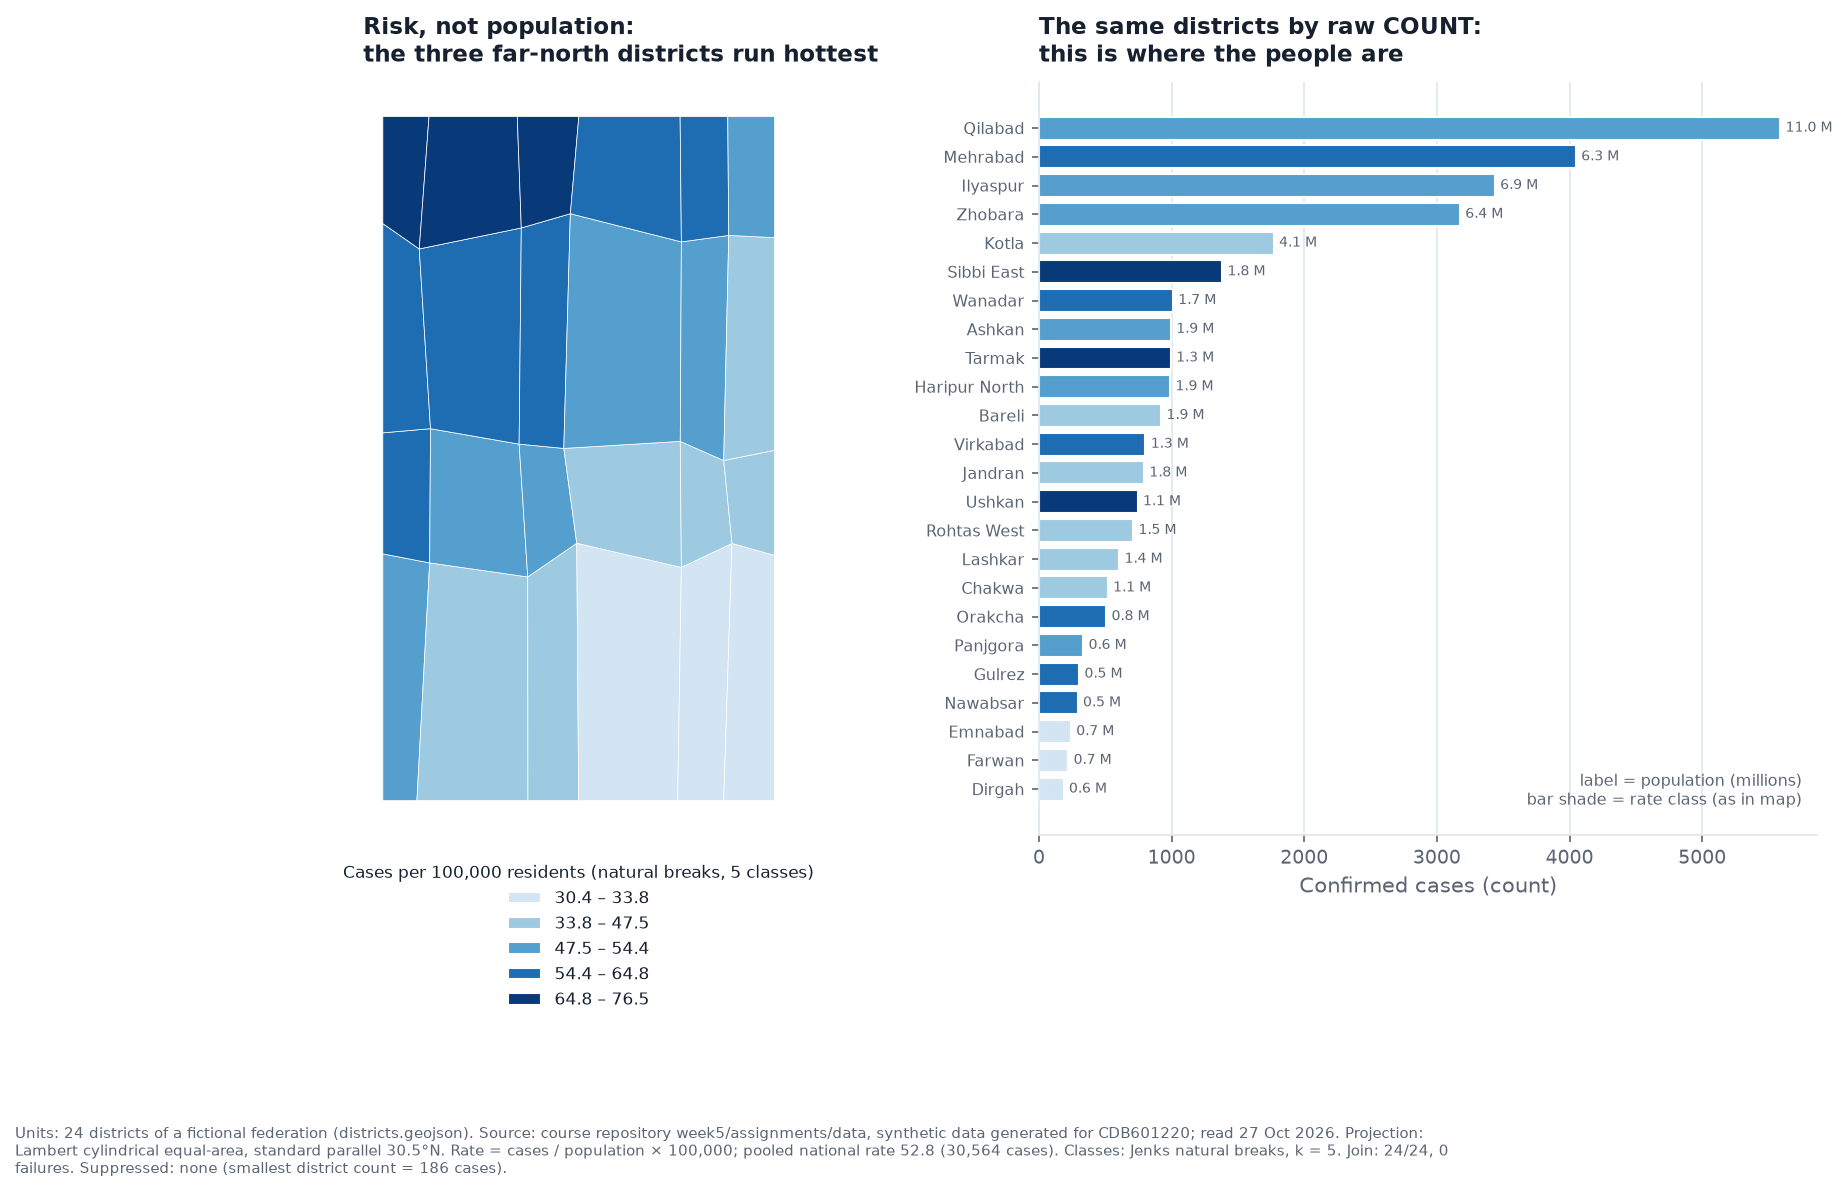

smallest district case count: 186 (no unit under any small-number threshold; nothing suppressed)


In [4]:
# 5 ── COLOUR: one sequential hue (Blues), dark = more, 5 steps; 6 ── CAPTION in the figure note below.
fig, (axm, axb) = plt.subplots(1, 2, figsize=(13.5, 7.6), gridspec_kw={"width_ratios": [0.85, 1], "wspace": 0.18})
fig.subplots_adjust(bottom=0.22)
rate_by_code = dict(zip(dh.code, dh.rate))
edges = g.choropleth(axm, feats, rate_by_code, scheme="natural", k=5,
                     legend_title="Cases per 100,000 residents (natural breaks, 5 classes)",
                     fmt="{:.1f}", legend_loc="upper center", legend_anchor=(0.5, -0.02))
axm.set_title("Risk, not population:\nthe three far-north districts run hottest", loc="left", fontsize=11)
print("printed class breaks:", np.round(edges, 1).tolist())

# the COUNT, back on as a sorted bar chart (slide 47 row 3), bars coloured by the same class shade
cm = plt.get_cmap(g.PALETTE["sequential"]); K = 5
shade = [cm(0.18 + 0.78 * c / (K - 1)) for c in range(K)]
d = dh.sort_values("cases")
cl = g.class_of(d.rate.to_numpy(), edges)
axb.barh(d.district, d.cases, color=[shade[i] for i in cl], edgecolor="white")
axb.set_xlabel("Confirmed cases (count)")
axb.set_title("The same districts by raw COUNT:\nthis is where the people are", loc="left", fontsize=11)
axb.tick_params(axis="y", labelsize=7.5)
axb.grid(axis="y", visible=False)
for y, (n, c_) in enumerate(zip(d.population / 1e6, d.cases)):
    axb.text(c_ + 40, y, f"{n:.1f} M", va="center", fontsize=6.5, color=PAL["ink_soft"])
axb.text(0.98, 0.04, "label = population (millions)\nbar shade = rate class (as in map)", transform=axb.transAxes,
         ha="right", fontsize=7.5, color=PAL["ink_soft"])
cap = (f"Units: 24 districts of a fictional federation (districts.geojson). Source: course repository week5/assignments/data, synthetic data "
       f"generated for CDB601220; read 27 Oct 2026. Projection: Lambert cylindrical equal-area, standard parallel {lat_ts:.1f}°N. "
       f"Rate = cases / population × 100,000; pooled national rate {pooled:.1f} (30,564 cases). Classes: Jenks natural breaks, k = 5. "
       f"Join: 24/24, 0 failures. Suppressed: none (smallest district count = {dh.cases.min()} cases).")
import textwrap
g.save_fig(fig, FIG + "partD_choropleth.png", note="\n".join(textwrap.wrap(cap, 190)))
plt.show()
print("smallest district case count:", dh.cases.min(), "(no unit under any small-number threshold; nothing suppressed)")

## Self-check (all reproduced above)

* 24 / 24 districts join, **0 failures**.
* Pooled national rate **52.8** per 100,000 from **30,564** cases.
* Top three by **rate**: D19, D20, D21 · by **count**: D17, D13, D09 · overlap **0**.
* r(cases, population) = **+0.986**; r(rate, population) ≈ **0.000**.

The legend title carries the denominator in words, the break edges are printed, and the count is shown beside the map as a sorted bar chart.